In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load dataset
df = pd.read_csv("house_price.csv")

df.head()

,area,rooms,price
0,2104,3,399900
1,1600,3,329900
2,2400,3,369000
3,1416,2,232000
4,3000,4,539900


In [27]:

X = df.drop("price", axis=1)
y = df["price"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Create and train model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluate
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 72334.7536035667
MSE: 8610424544.77767
R2 Score: 0.5148848812741442


In [17]:
df.duplicated().sum()
df.isnull().sum()

area     0
rooms    0
price    0
dtype: int64

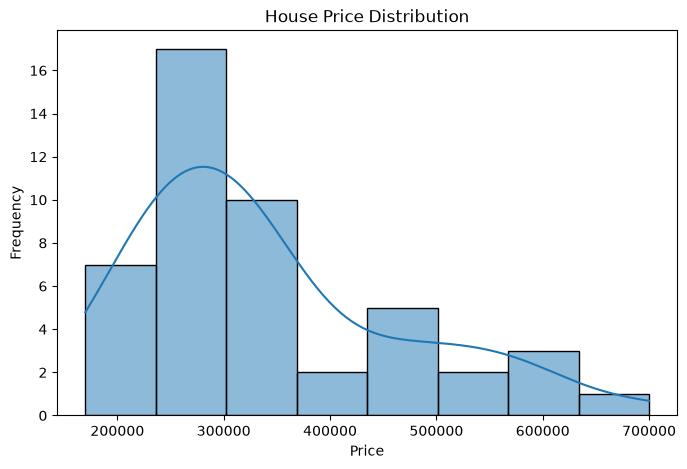

In [18]:
import seaborn as sns

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.histplot(df["price"], kde=True)
plt.title("House Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

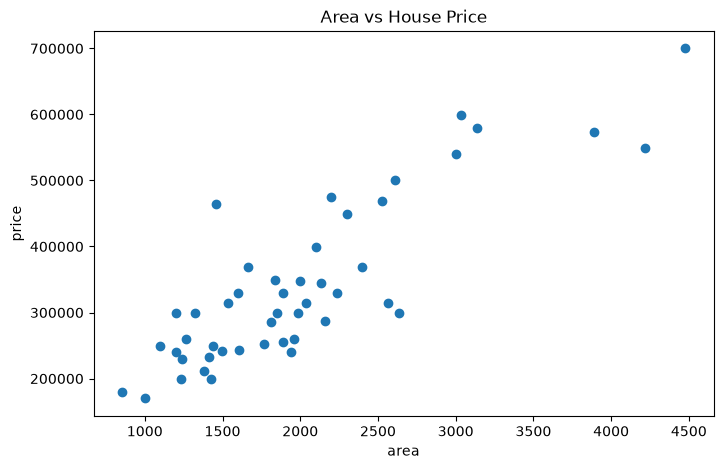

In [19]:
plt.figure(figsize=(8,5))
plt.scatter(df['area'],df['price'])

plt.xlabel("area")
plt.ylabel("price")

plt.title("Area vs House Price")
plt.show()

In [20]:
df.corr(numeric_only = True)

,area,rooms,price
area,1.000000,0.559967,0.854988
rooms,0.559967,1.000000,0.442261
price,0.854988,0.442261,1.000000


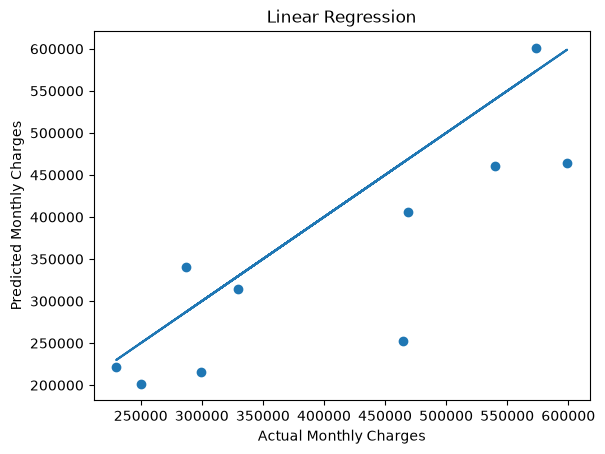

In [25]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred)

plt.plot(
    y_test, y_test
)

plt.xlabel("Actual Monthly Charges")
plt.ylabel("Predicted Monthly Charges")
plt.title("Linear Regression")

plt.show()